# 4. Fine-tuning: which parts of the model to train

Four ways to fine-tune the base model on 60 h of DL Sprint training clips: full fine-tuning, LoRA, decoder only and
encoder only. The diagnosis predicts that training the decoder (where spelling lives) matters most; five predictions
were written down before training.

In [1]:
from nbutil import *
import pandas as pd

In [2]:
M = "results/modal/finetuned/{}/"
wer_table({"zero-shot": ZERO_SHOT, "full fine-tuning (M1)": M + "m1_full", "LoRA": [M + "m1_lora", "results/kaggle/finetuned/{}/m1_lora_t4"],
           "decoder only": M + "m1_decoder", "encoder only": M + "m1_encoder"})

,DL Sprint eval,FLEURS,Common Voice,Kathbath
zero-shot,22.70,21.54,14.80,14.81
full fine-tuning (M1),11.34,18.34,12.80,13.48
LoRA,11.76,18.40,12.84,13.61
decoder only,12.99,18.61,13.13,13.62
encoder only,13.83,19.90,14.69,14.59


LoRA's Common Voice and Kathbath rows were scored on a Kaggle T4; the same model gives the same WER on the T4 and the A100 within 0.01 points.

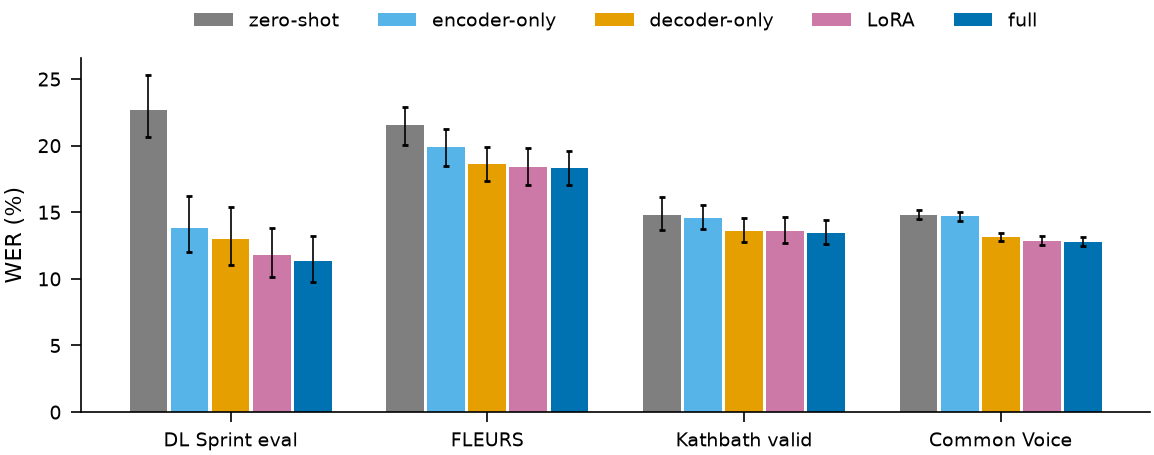

In [3]:
figure("f4_finetune_by_set")

In [4]:
pd.DataFrame({s: paired(f"finetuning/{s}__m1_full_vs_tugstugi_a100") for s in SETS}).T

,A,B,B - A,95% CI,significant
splits_fa-eval,22.7,11.34,-11.36,"[-12.32, -10.46]",True
fleurs-test,21.54,18.34,-3.2,"[-4.07, -2.27]",True
cv-test,14.8,12.8,-2.0,"[-2.23, -1.77]",True
kathbath-valid,14.81,13.48,-1.33,"[-2.00, -0.69]",True


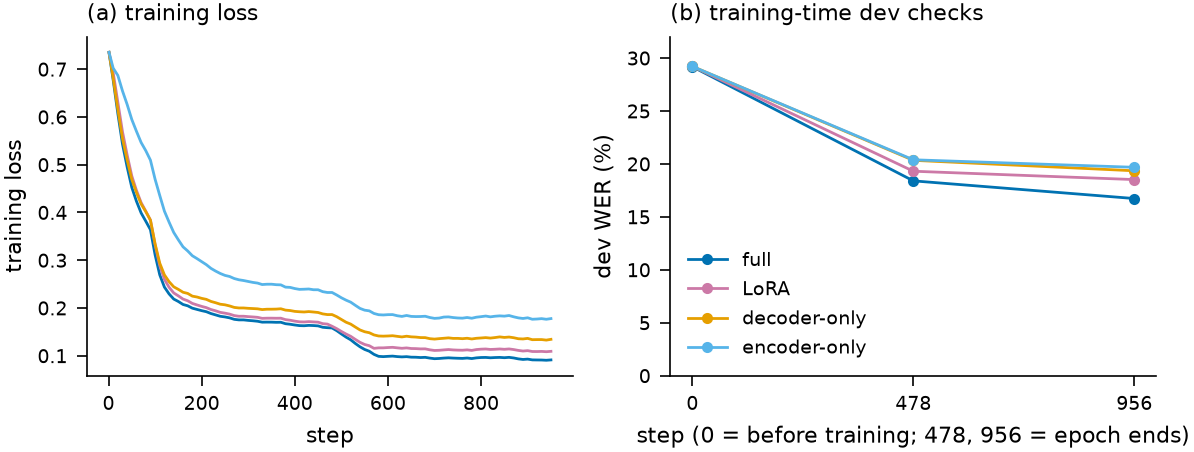

In [5]:
figure("f12_training_curves")

Fine-tuning removes the spelling errors first:

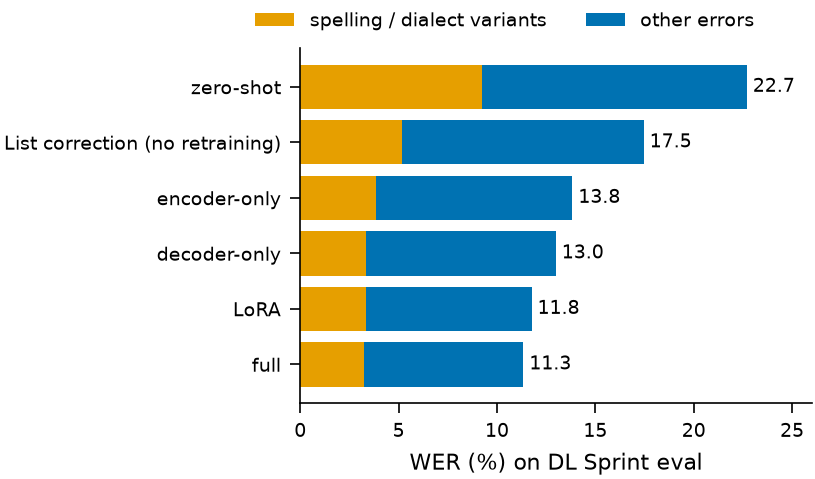

In [6]:
figure("f5_gain_by_error_type", 450)

Rescoring on top of the fine-tuned model adds little: the errors it could reach are gone.

In [7]:
st = pd.read_csv(ROOT / "results/stacking/summary.csv").set_index("set")
(100 * st[["greedy_wer", "rover_wer", "mbr_lm_x_wer", "oracle_pool_wer"]]).round(2).rename(columns={
    "greedy_wer": "M1 greedy", "rover_wer": "ROVER", "mbr_lm_x_wer": "LM-MBR expanded", "oracle_pool_wer": "oracle"})

,M1 greedy,ROVER,LM-MBR expanded,oracle
set,,,,
splits_fa-dev,16.74,16.08,16.19,13.17
splits_fa-eval,11.34,10.89,11.01,8.21
fleurs-test,18.34,17.90,18.03,14.43
kathbath-valid,13.48,13.29,13.34,9.64


In [8]:
record("results/modal/finetuned/splits_fa-eval/m1_full/run_info.json")

**Run record** `results/modal/finetuned/splits_fa-eval/m1_full/run_info.json`  
`python /root/proj/pipeline/eval_zero_shot.py --manifest data/splits_fa/eval.csv --model checkpoints/m1_full/final --name m1_full --out_dir results/finetuned --batch_size 8`  
commit `` · started 2026-10-09T22:43:47 · 0.9 s · torch 2.13.0+cu130, transformers ?, GPU NVIDIA A100-SXM4-40GB

**Next:** the in-domain model is strong on DL Sprint but weaker on read speech. Notebook 5 trains on the other public
corpora too and asks how to mix them.